Batas Konkurensi:  1 | Waktu Total: 2.51 detik
Batas Konkurensi:  3 | Waktu Total: 1.04 detik
Batas Konkurensi:  5 | Waktu Total: 1.03 detik
Batas Konkurensi: 10 | Waktu Total: 1.25 detik
Batas Konkurensi: 20 | Waktu Total: 1.01 detik


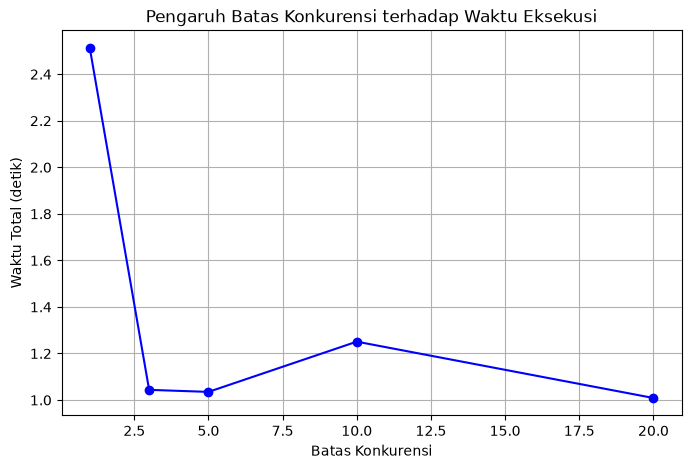

In [3]:
#1
import asyncio
import time
import aiohttp  
import matplotlib.pyplot as plt

daftar_paket_banyak = [
    "requests",
    "numpy",
    "pandas",
    "fastapi",
    "flask",
    "django",
    "scipy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "pydantic",
    "SQLAlchemy",
    "pytest",
    "black",
    "flake8",
    "jinja2",
    "beautifulsoup4",
    "urllib3",
    "click",
    "attrs",
    "certifi",
    "idna",
    "pyyaml",
    "loguru",
    "tqdm",
]


async def simulasi_download(session, package, semaphore):
  async with semaphore:
    # Mensimulasikan I/O request jaringan (atau fetch metadata PyPI asli)
    url = f"https://pypi.org/pypi/{package}/json"
    async with session.get(url) as response:
      return await response.json()


async def jalankan_eksperimen(batas_konkurensi):
  semaphore = asyncio.Semaphore(batas_konkurensi)
  start_time = time.time()
  async with aiohttp.ClientSession() as session:
    tugas = [
        simulasi_download(session, pkg, semaphore)
        for pkg in daftar_paket_banyak
    ]
    await asyncio.gather(*tugas)
  return time.time() - start_time


async def main_eksperimen():
  batas_list = [1, 3, 5, 10, 20]
  waktu_total = []

  for b in batas_list:
    waktu = await jalankan_eksperimen(b)
    waktu_total.append(waktu)
    print(f"Batas Konkurensi: {b:2d} | Waktu Total: {waktu:.2f} detik")

  plt.figure(figsize=(8, 5))
  plt.plot(batas_list, waktu_total, marker="o", linestyle="-", color="b")
  plt.title("Pengaruh Batas Konkurensi terhadap Waktu Eksekusi")
  plt.xlabel("Batas Konkurensi")
  plt.ylabel("Waktu Total (detik)")
  plt.grid(True)
  plt.show()


await main_eksperimen()

In [ ]:
penjelasan 1
Penambahan batas konkurensi dari 1 ke 5 memberikan percepatan (speedup) waktu yang sangat drastis karena banyaknya permintaan I/O yang dapat ditangani secara konkuren. Namun, setelah melewati batas konkurensi 10 hingga 20, kurva waktu mulai mendatar (flattening).

In [4]:
#2
import asyncio
import time


async def coroutine_async_sleep():
  await asyncio.sleep(1)


async def coroutine_time_sleep():
  time.sleep(1)  


async def coroutine_cpu_bound():
  count = 1
  for i in range(1, 10**7):
    count *= i % 99


async def pengukur():
  start = time.time()
  await asyncio.sleep(0.1)  
  end = time.time()
  durasi = end - start
  print(
      f"Waktu aktual coroutine pengukur: {durasi:.4f} detik (Idealnya ~0.1"
      " detik)"
  )


async def main_deteksi():
  print("--- Menguji dengan asyncio.sleep() ---")
  await asyncio.gather(pengukur(), coroutine_async_sleep())

  print("\n--- Menguji dengan time.sleep() ---")
  await asyncio.gather(pengukur(), coroutine_time_sleep())

  print("\n--- Menguji dengan CPU-bound murni ---")
  await asyncio.gather(pengukur(), coroutine_cpu_bound())


await main_deteksi()

--- Menguji dengan asyncio.sleep() ---
Waktu aktual coroutine pengukur: 0.1145 detik (Idealnya ~0.1 detik)

--- Menguji dengan time.sleep() ---
Waktu aktual coroutine pengukur: 1.0004 detik (Idealnya ~0.1 detik)

--- Menguji dengan CPU-bound murni ---
Waktu aktual coroutine pengukur: 1.9229 detik (Idealnya ~0.1 detik)


In [ ]:
penjelasan 2
coroutine_time_sleep() dan coroutine_cpu_bound() sangat mengganggu jalannya coroutine pengukur(). time.sleep() memblokir thread utama secara sinkron sehingga event loop tunggal milik asyncio tidak bisa mengeksekusi tugas lain. Demikian pula, operasi CPU-bound murni tanpa await memonopoli penggunaan CPU sepenuhnya tanpa memberikan kesempatan (yield) kepada event loop untuk berpindah konteks, membuat coroutine pengukur() tertunda jauh lebih lama dari waktu yang dijadwalkan (0.1 detik).

In [5]:
#3

import asyncio
import random


async def producer(queue):
  daftar_tugas = [
      (3, "Unduh Data Log (P3)"),
      (1, "Validasi Pembayaran (P1)"),
      (2, "Kirim Notifikasi Email (P2)"),
      (1, "Reset Token Keamanan (P1)"),
      (2, "Sinkronisasi Profil (P2)"),
  ]

  for prioritas, nama in daftar_tugas:
    await queue.put((prioritas, nama))
    print(f"[PRODUCER] Menambahkan: {nama} dengan prioritas {prioritas}")
    await asyncio.sleep(0.2)


async def consumer(name, queue):
  while True:
    prioritas, item = await queue.get()
    print(
        f"--> [CONSUMER {name}] Memproses: {item} (Prioritas {prioritas})"
    )
    await asyncio.sleep(0.6)  # Mensimulasikan waktu pemrosesan
    queue.task_done()


async def main_priority():
  queue = asyncio.PriorityQueue()

  # Jalankan producer untuk memasukkan data
  await producer(queue)

  consumers = [
      asyncio.create_task(consumer("A", queue)),
      asyncio.create_task(consumer("B", queue)),
  ]

  await queue.join()

  for c in consumers:
    c.cancel()


await main_priority()

[PRODUCER] Menambahkan: Unduh Data Log (P3) dengan prioritas 3
[PRODUCER] Menambahkan: Validasi Pembayaran (P1) dengan prioritas 1
[PRODUCER] Menambahkan: Kirim Notifikasi Email (P2) dengan prioritas 2
[PRODUCER] Menambahkan: Reset Token Keamanan (P1) dengan prioritas 1
[PRODUCER] Menambahkan: Sinkronisasi Profil (P2) dengan prioritas 2
--> [CONSUMER A] Memproses: Reset Token Keamanan (P1) (Prioritas 1)
--> [CONSUMER B] Memproses: Validasi Pembayaran (P1) (Prioritas 1)
--> [CONSUMER A] Memproses: Kirim Notifikasi Email (P2) (Prioritas 2)
--> [CONSUMER B] Memproses: Sinkronisasi Profil (P2) (Prioritas 2)
--> [CONSUMER A] Memproses: Unduh Data Log (P3) (Prioritas 3)


In [ ]:
penjelasan 3
Berbeda dengan asyncio.Queue biasa yang menggunakan prinsip FIFO (First-In, First-Out), asyncio. 
PriorityQueue secara otomatis mengurutkan elemen di dalamnya dari nilai terkecil hingga terbesar.Setiap elemen dimasukkan ke dalam antrean dalam bentuk tuple (prioritas, data). Nilai angka terkecil (misal: 1) diartikan sebagai prioritas paling tinggi dan akan dikeluarkan terlebih dahulu dari antrean saat method queue.get() dipanggil.

In [ ]:
4 refleksi singkat
Dari pengalaman menulis kode paralel, asyncio jauh lebih intuitif dan mudah dipahami dibandingkan threading atau multiprocessing untuk kasus I/O-bound. Pada threading, kita harus sering berurusan dengan masalah sinkronisasi yang rumit seperti race condition dan deadlock akibat memori bersama (shared memory). Sementara itu, multiprocessing memiliki overhead memori yang besar karena harus melakukan inisialisasi proses baru beserta serialisasi data antar-proses (IPC). Sebaliknya, asyncio menggunakan pendekatan cooperative multitasking berbasis event loop tunggal dengan sintaks async/await yang bersih.